# FlashPoint EdgeCenter — batch position reconstruction

This batch notebook follows the analysis sequence and plotting conventions of `FlashPoint_clean_posreco.ipynb` as closely as possible.

For every selected `output_edge*_array*_*` directory it runs the same staged reconstruction:

1. SiPM geometry / COG
2. ROOT + timing feature loading
3. truth/amplitude standardization
4. dN/dt rebinning + train/test split
5. common metrics
6. conventional COG
7. amplitude Poisson template
8. HGB amplitude/timing stages
9. full spatiotemporal Poisson likelihood
10. optional ExtraTrees
11. final comparison
12. approximate CRLB + spatial resolution/bias/RMSE maps
13. optional timing-bin scan
14. optional true detector timing-resolution scan

**Important sparse fix:** row counts always use `q.shape[0]`, never `len(q)`, because SciPy sparse matrices deliberately make `len(q)` ambiguous.


In [135]:

# 0. Imports + batch configuration
from pathlib import Path
import gc, re, warnings
from scipy import sparse
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor

SEED = 42

BASE = Path("/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter")
CASE_GLOB = "output_edge*_array*_*"

# Run every matching directory, or select only CASE_NAMES.
RUN_ALL_CASES = False
CASE_NAMES = [
    # "output_edge8_array8_1000",
    # "output_edge9_array9_1000",
    "output_edge10_array10_1000",
    # "output_edge11_array11_1000",
    # "output_edge15_array6_1000",
    # "output_edge15_array8_1000",
    # "output_edge15_array10_1000",
    # "output_edge18_array6_1000",
    # "output_edge18_array8_1000",
    # "output_edge20_array4_1000",
    # "output_edge20_array6_1000",
    # "output_edge20_array8_1000",
    # "output_edge22_array6_1000",
    # "output_edge24_array4_1000",
    # "output_edge24_array6_1000",
    # "output_edge24_array8_1000",
]

# Optional quick debugging: None = use every ROOT file in each case.
MAX_ROOT_FILES = None

# Train/test + response-map settings
TRAIN_FRAC = 0.70
GRID_N = 40
MIN_CELL = 10
POSTERIOR_K = 9
LIKELIHOOD_CHUNK = 2000
FEATURE_CHUNK = 2000
HIST_DTYPE = np.uint16

# Timing
APPLY_TIMING_SMEARING = True
TIMING_SIGMA_PS = 300
DT_FINE_NS = 0.05
EARLY_NS = 3.0
DND_REBIN = 2
NBIN_FINE = int(round(EARLY_NS / DT_FINE_NS))

# Nonlinear regression
HGB_MAX_ITER = 180
HGB_LEAVES = 31
ML_TRAIN_MAX = 100_000

# Optional expensive studies
RUN_EXTRA_TREES = True
RUN_TIMING_BIN_SCAN = False
RUN_TRUE_TIMING_SCAN = False
SIGMA_T_PS = [0, 50, 100, 150, 200, 250, 300, 400, 500, 750, 1000]

# Keep full prediction arrays only while a case is being processed.
# The batch-level output stores compact CSV summaries.
SAVE_PREDICTIONS_NPZ = False

if not BASE.exists():
    raise FileNotFoundError(f"BASE does not exist: {BASE}")

if not (0 < TRAIN_FRAC < 1) or GRID_N < 2 or MIN_CELL < 1:
    raise ValueError("Invalid train/grid configuration")
if DT_FINE_NS <= 0 or EARLY_NS <= 0 or not np.isclose(NBIN_FINE * DT_FINE_NS, EARLY_NS):
    raise ValueError("EARLY_NS must be a positive exact multiple of DT_FINE_NS")
if TIMING_SIGMA_PS < 0 or POSTERIOR_K < 1:
    raise ValueError("Invalid timing/interpolation configuration")


In [136]:

# 1. Discover cases
CASE_RE = re.compile(r"^output_edge(?P<edge>\d+)_array(?P<array>\d+)_(?P<length>\d+)$")

def parse_case(case_dir):
    m = CASE_RE.match(case_dir.name)
    if m is None:
        raise ValueError(f"Unrecognized case name: {case_dir.name}")
    return {k: int(v) for k, v in m.groupdict().items()}

if RUN_ALL_CASES:
    CASE_DIRS = []
    for p in sorted(BASE.glob(CASE_GLOB)):
        if p.is_dir() and CASE_RE.match(p.name):
            CASE_DIRS.append(p)
else:
    CASE_DIRS = [BASE / name for name in CASE_NAMES]

if not CASE_DIRS:
    raise FileNotFoundError(f"No cases found under {BASE}")

case_table = []
for p in CASE_DIRS:
    q = parse_case(p)
    q["case"] = p.name
    q["n_sipm"] = 4 + 4*q["edge"] + q["array"]**2
    q["root_files"] = len(list(p.glob("*.root")))
    case_table.append(q)

case_table = pd.DataFrame(case_table).sort_values(["n_sipm", "edge", "array"]).reset_index(drop=True)
display(case_table)
print(f"Discovered {len(case_table)} case(s)")


,edge,array,length,case,n_sipm,root_files
0,10,10,1000,output_edge10_array10_1000,144,20


Discovered 1 case(s)



## Geometry convention

The four corner SiPM centers keep the original notebook's optical-contact offset,

$$
{\rm EDGE}=\frac{L}{2}-2.1460690809~{\rm mm}.
$$

The four edge sequences follow the existing channel ordering. The center array uses the Geant4 placement convention

$$
x_i=-\frac L2+\frac{L}{N_{\rm array}+1}(i+1),\qquad
y_j=-\frac L2+\frac{L}{N_{\rm array}+1}(j+1).
$$

Thus the center-array channel order is row-major in `(j, i)` after all perimeter channels.


In [137]:

# 2. Shared helpers

TIME_NAMES = ["t_plot_ns", "t_ns", "time_ns", "arrival_time_ns", "global_time_ns"]

def get_POS(nedge, narray, length):
    half = length / 2.0
    edge = half - 2.1460690809

    pos = [
        [ edge,  edge],
        [-edge,  edge],
        [-edge, -edge],
        [ edge, -edge],
    ]

    if nedge:
        u = np.linspace(-edge, edge, nedge + 2)[1:-1]
        pos += [[ x,  edge] for x in u]       # +Y: left -> right
        pos += [[ edge, -y] for y in u]       # +X: top -> bottom
        pos += [[-x, -edge] for x in u]       # -Y: right -> left
        pos += [[-edge,  y] for y in u]       # -X: bottom -> top

    if narray:
        # Exact central-grid convention used in the EdgeCenter geometry.
        u = np.linspace(-half, half, narray + 2)[1:-1]
        pos += [[x, y] for y in u for x in u]

    out = np.asarray(pos, dtype=float)
    expected = 4 + 4*nedge + narray*narray
    if len(out) != expected:
        raise RuntimeError(f"Geometry has {len(out)} positions, expected {expected}")
    return out

def integer_ids(values, label):
    values = np.asarray(values)
    if not np.isfinite(values).all() or not np.equal(values, np.floor(values)).all():
        raise ValueError(f"{label} must contain finite integer IDs")
    return values.astype(np.int64)

def training_medians(X):
    med = np.zeros(X.shape[1], dtype=X.dtype)
    finite_columns = np.isfinite(X).any(0)
    med[finite_columns] = np.nanmedian(X[:, finite_columns], axis=0)
    return med

def savefig(fig, path):
    fig.tight_layout()
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [ ]:

# 3. Single-case analysis
def analyze_case(case_dir):
    info = parse_case(case_dir)
    NEDGE = info["edge"]
    NARRAY = info["array"]
    LENGTH = info["length"]
    HALF = LENGTH / 2.0
    NSIPM = 4 + 4*NEDGE + NARRAY**2

    OUT = case_dir.parent / f"{case_dir.name}_spatiotemporal"
    OUT.mkdir(parents=True, exist_ok=True)

    FILES = sorted(case_dir.glob("*.root"))
    if MAX_ROOT_FILES is not None:
        FILES = FILES[:MAX_ROOT_FILES]
    if not FILES:
        raise FileNotFoundError(f"No ROOT files found in {case_dir}")

    print("\n" + "="*90)
    print(f"{case_dir.name}: edge={NEDGE}, array={NARRAY}, L={LENGTH} mm, NSIPM={NSIPM}")
    print(f"ROOT files={len(FILES)}")
    print(f"OUT={OUT}")
    print("="*90)

    POS = get_POS(NEDGE, NARRAY, LENGTH)
    assert len(POS) == NSIPM

    # ------------------------------------------------------------------
    # 1. Exact SiPM optical-contact positions used for conventional COG
    # ------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(11, 9))
    ax.scatter(POS[:, 0], POS[:, 1])
    for i, (x, y) in enumerate(POS):
        ax.text(x, y, str(i), ha="center", va="center", fontsize=8)
    ax.set(
        xlabel="X [mm]", ylabel="Y [mm]", aspect="equal",
        xlim=(-(HALF+50), HALF+50), ylim=(-(HALF+50), HALF+50),
        title=f"{case_dir.name} — {NSIPM} SiPMs"
    )
    ax.tick_params(labelsize=14)
    ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15); ax.title.set_size(16)
    ax.grid(alpha=.25)
    savefig(fig, OUT/"sipm_layout.png")

    # ------------------------------------------------------------------
    # 2. Load ROOT files and build timing features
    # ------------------------------------------------------------------
    def read_hit_arrays(f, local):
        if len(np.unique(local)) != len(local):
            raise ValueError("Duplicate local event IDs; hit-to-event mapping is ambiguous")
        if "hits" not in f:
            raise KeyError("Missing hits tree: timing studies require complete hit information")
        tree = f["hits"]
        thit = next((x for x in TIME_NAMES if x in tree.keys()), None)
        if thit is None:
            raise KeyError(f"No timing branch found; tried {TIME_NAMES}")
        h = tree.arrays(["event", "sipm", thit], library="np")
        ev = integer_ids(h["event"], "hits.event")
        sipm = integer_ids(h["sipm"], "hits.sipm")
        tm = np.asarray(h[thit], dtype=np.float64)
        row = pd.Index(local).get_indexer(ev)
        if (row < 0).any() or ((sipm < 0) | (sipm >= NSIPM)).any() or not np.isfinite(tm).all():
            raise ValueError("Unmapped event, out-of-range SiPM or nonfinite hit time")
        return row, sipm, tm

    def timing_features(row, sipm, tm, n, sigma_ps, rg, with_dnd=True):
        tm = tm.copy()
        if sigma_ps:
            tm += rg.normal(0, sigma_ps/1000.0, len(tm))

        t0 = np.full(n, np.inf)
        np.minimum.at(t0, row, tm)
        dt = tm - t0[row]

        group = row*NSIPM + sipm
        order = np.lexsort((tm, group))
        gs = group[order]
        starts = np.flatnonzero(np.r_[True, gs[1:] != gs[:-1]]) if len(gs) else np.empty(0, int)
        ends = np.r_[starts[1:], len(gs)]

        times = []
        for k in range(3):
            target = np.full((n, NSIPM), np.nan, np.float32)
            take = starts[starts+k < ends] + k
            target.ravel()[gs[take]] = dt[order[take]]
            times.append(target)

        if not with_dnd:
            return (*times, None)

        dnd = np.zeros((n, NSIPM, NBIN_FINE), dtype=HIST_DTYPE)
        early = dt < EARLY_NS
        b = np.floor(dt[early] / DT_FINE_NS).astype(np.int64)
        inside = (b >= 0) & (b < NBIN_FINE)
        flat = group[early][inside]*NBIN_FINE + b[inside]
        occupied, count = np.unique(flat, return_counts=True)
        if len(count) and count.max() > np.iinfo(HIST_DTYPE).max:
            raise OverflowError("Histogram overflow: set HIST_DTYPE=np.uint32")
        dnd.ravel()[occupied] = count
        return (*times, dnd)

    # ------------------------------------------------------------------
    # 2. Load events + derive T1/T2/T3 and 50-ps dN/dt file-by-file
    # ------------------------------------------------------------------
    file_sizes = []
    for fname in FILES:
        with uproot.open(fname) as f:
            file_sizes.append(int(f["events"].num_entries))

    ntotal = sum(file_sizes)
    T1 = np.full((ntotal, NSIPM), np.nan, np.float32)
    T2 = np.full_like(T1, np.nan)
    T3 = np.full_like(T1, np.nan)
    DND_FINE = np.zeros((ntotal, NSIPM, NBIN_FINE), dtype=HIST_DTYPE)

    E = []
    offset = 0
    rng_smear = np.random.default_rng(SEED + 100)

    amp_cols = [f"n_detected_sipm{i}" for i in range(NSIPM)]

    for job, (fname, n) in enumerate(zip(FILES, file_sizes)):
        with uproot.open(fname) as f:
            e = pd.DataFrame(f["events"].arrays(library="np"))
            if len(e) != n:
                raise ValueError(f"Event row count changed in {fname}")
            missing = [c for c in amp_cols if c not in e]
            if missing:
                raise KeyError(
                    f"{fname.name}: expected {NSIPM} amplitude branches. "
                    f"Missing first branches: {missing[:5]}"
                )

            local = integer_ids(e["event"] if "event" in e else np.arange(n), "events.event")
            row, sipm, tm = read_hit_arrays(f, local)

            amplitude = e[amp_cols].to_numpy(float)
            hit_count = np.bincount(
                row*NSIPM + sipm, minlength=n*NSIPM
            ).reshape(n, NSIPM)

            if not np.array_equal(amplitude, hit_count):
                raise ValueError(
                    f"{fname.name}: hit counts disagree with amplitude branches; "
                    "check that hits contains exactly the detected photons"
                )

            t1, t2, t3, dnd = timing_features(
                row, sipm, tm, n,
                TIMING_SIGMA_PS if APPLY_TIMING_SMEARING else 0,
                rng_smear
            )

            sl = slice(offset, offset+n)
            T1[sl] = t1
            T2[sl] = t2
            T3[sl] = t3
            DND_FINE[sl] = dnd

            e["event_local"] = local
            e["job"] = job
            e["event"] = np.arange(offset, offset+n)
            E.append(e)
            offset += n

            print(f"{job:3d} {fname.name:42s} events={n:6d}")
            del row, sipm, tm, hit_count, amplitude, t1, t2, t3, dnd

    events = pd.concat(E, ignore_index=True).replace([np.inf, -np.inf], np.nan)
    del E, e

    # 3. Standardize truth + amplitude arrays
    def first(df, names):
        return next((x for x in names if x in df), None)

    XCOL = first(events, ["source_x_mm", "x_source_mm", "source_x", "x_true_mm"])
    YCOL = first(events, ["source_y_mm", "y_source_mm", "source_y", "y_true_mm"])
    if XCOL is None or YCOL is None:
        raise KeyError("Truth X/Y branches not found")

    truth = events[[XCOL, YCOL]].to_numpy(float)
    A = events[amp_cols].to_numpy(float)

    if not np.isfinite(A).all() or (A < 0).any() or not np.equal(A, np.floor(A)).all():
        raise ValueError("Amplitude branches must contain finite nonnegative integer counts")

    Ntot = A.sum(1)
    F = A / np.where(Ntot[:, None] > 0, Ntot[:, None], np.nan)
    logN = np.log1p(Ntot)[:, None]

    good = (
        np.isfinite(truth).all(1) &
        (Ntot > 0) &
        (np.abs(truth) <= HALF).all(1)
    )

    print("Excluded invalid/zero-photon/out-of-detector events:", int((~good).sum()))

    events = events.loc[good].reset_index(drop=True)
    truth = truth[good]
    A = A[good]
    F = F[good]
    logN = logN[good]
    T1 = T1[good]
    T2 = T2[good]
    T3 = T3[good]
    DND_FINE = DND_FINE[good]
    Ntot = Ntot[good]

    print("Usable events:", len(truth))
    print("Mean detected photons/event:", Ntot.mean())
    print("Mean perimeter photons/event:", A[:, :4+4*NEDGE].sum(1).mean())
    if NARRAY:
        print("Mean center-array photons/event:", A[:, 4+4*NEDGE:].sum(1).mean())

    # ------------------------------------------------------------------
    # 4. Rebin early dN/dt + train/test split
    # ------------------------------------------------------------------
    def rebin_dnd(dnd, factor):
        if not isinstance(factor, (int, np.integer)) or factor < 1 or dnd.shape[2] % factor:
            raise ValueError("Rebin factor must be positive and divide the full time window")
        if factor == 1:
            return dnd
        shape = (*dnd.shape[:2], dnd.shape[2]//factor)
        result = np.empty(shape, dtype=np.uint32)
        for s in range(0, len(dnd), FEATURE_CHUNK):
            block = dnd[s:s+FEATURE_CHUNK]
            reduced = block.reshape(
                len(block), shape[1], shape[2], factor
            ).sum(3, dtype=np.uint64)
            if reduced.size and reduced.max() > np.iinfo(np.uint32).max:
                raise OverflowError("Rebinned histogram exceeds uint32")
            result[s:s+len(block)] = reduced
        return result

    DND = rebin_dnd(DND_FINE, DND_REBIN)
    DT_MAIN_NS = DT_FINE_NS * DND_REBIN

    rng = np.random.default_rng(SEED)
    idx = rng.permutation(len(truth))
    ntr = int(TRAIN_FRAC * len(idx))
    if ntr < 2 or ntr >= len(idx):
        raise ValueError("Need at least two training events and one test event")
    itr, ite = idx[:ntr], idx[ntr:]
    itr_ml = itr if len(itr) <= ML_TRAIN_MAX else rng.choice(
        itr, ML_TRAIN_MAX, replace=False
    )

    print(f"train={len(itr):,}, test={len(ite):,}, ML train={len(itr_ml):,}")

    # ------------------------------------------------------------------
    # 5. Common metrics + plotting helpers
    # ------------------------------------------------------------------
    def metrics(name, xy):
        xy = np.asarray(xy)
        if xy.shape != (len(ite), 2):
            raise ValueError("Predictions must align with held-out event rows")
        m = np.isfinite(xy).all(1)
        if not m.any():
            return dict(
                method=name, N=0, coverage=0.0,
                **{k: np.nan for k in (
                    "bias_x_mm", "bias_y_mm", "sigma_x_mm", "sigma_y_mm",
                    "sigma_xy_mm", "RMSE_xy_mm", "R68_mm", "R90_mm"
                )}
            )
        d = xy[m] - truth[ite][m]
        dx, dy = d[:, 0], d[:, 1]
        r = np.hypot(dx, dy)
        sx, sy = np.std(dx), np.std(dy)
        return dict(
            method=name, N=m.sum(), coverage=m.mean(),
            RMSE_xy_mm=np.sqrt(np.mean(d*d)),
            bias_x_mm=dx.mean(), bias_y_mm=dy.mean(),
            sigma_x_mm=sx, sigma_y_mm=sy,
            sigma_xy_mm=np.sqrt((sx*sx + sy*sy)/2),
            R68_mm=np.quantile(r, .68),
            R90_mm=np.quantile(r, .90)
        )

    def performance(name, xy, bins=60):
        xt, yt = truth[ite].T
        xr, yr = xy.T
        m = np.isfinite(xr) & np.isfinite(yr)
        if not m.any():
            warnings.warn(f"No finite predictions for {name}")
            return

        xt, yt, xr, yr = xt[m], yt[m], xr[m], yr[m]
        dx, dy = xr-xt, yr-yt
        rr = np.hypot(dx, dy)

        fig, ax = plt.subplots(2, 2, figsize=(15, 12))
        for a, t, r, lab in [
            (ax[0,0], xt, xr, "X"),
            (ax[0,1], yt, yr, "Y"),
        ]:
            h = a.hist2d(t, r, bins=bins, range=[[-HALF, HALF]]*2)
            a.plot([-HALF, HALF], [-HALF, HALF], "--", lw=1)
            a.set(xlabel=f"Truth {lab} [mm]", ylabel=f"Reco {lab} [mm]")
            c = plt.colorbar(h[3], ax=a, label="Events / bin")
            c.ax.tick_params(labelsize=16)
            c.set_label("Events / bin", fontsize=16)

        ax[1,0].hist(
            dx, 100, (-HALF, HALF), histtype="step", density=True, linewidth=2,
            label=fr"X $\sigma$={np.std(dx):.1f} mm"
        )
        ax[1,0].hist(
            dy, 100, (-HALF, HALF), histtype="step", density=True, linewidth=2,
            label=fr"Y $\sigma$={np.std(dy):.1f} mm"
        )
        ax[1,0].set(xlabel="Reco - truth [mm]", ylabel="Density")
        ax[1,0].legend(fontsize=16)

        rs = np.sort(rr)
        ax[1,1].plot(rs, np.arange(1, len(rs)+1)/len(rs), linewidth=2)
        ax[1,1].axhline(.68, ls="--")
        ax[1,1].axhline(.90, ls="--")
        ax[1,1].set(
            xlabel="Radial error [mm]", ylabel="CDF",
            title=f"R68={np.quantile(rr,.68):.1f}, R90={np.quantile(rr,.90):.1f} mm"
        )

        for a in ax.flat:
            a.tick_params(labelsize=16)
            a.xaxis.label.set_size(16)
            a.yaxis.label.set_size(16)
            a.title.set_size(16)

        fig.suptitle(name, fontsize=16)
        savefig(fig, OUT/"best_model_performance.png")

    # 6. Conventional COG baselines
    pred = {}

    def cog(Ax, pos):
        s = Ax.sum(1)
        out = np.full((len(Ax), 2), np.nan)
        m = s > 0
        out[m] = Ax[m] @ pos / s[m, None]
        return out

    nperim = 4 + 4*NEDGE
    pred["COG corners only"] = cog(A[ite, :4], POS[:4])
    pred["COG all SiPMs"] = cog(A[ite], POS)

    # ------------------------------------------------------------------
    # 7. Regular template builder + fast Poisson reconstruction
    # ------------------------------------------------------------------
    XY_EDGES = np.linspace(-HALF, HALF, GRID_N+1)
    XY_CENTERS = (XY_EDGES[:-1] + XY_EDGES[1:]) / 2

    def grid_ids(xy):
        xy = np.asarray(xy)
        if not np.isfinite(xy).all() or (np.abs(xy) > HALF).any():
            raise ValueError("Template/map coordinates must be finite and inside detector")
        ix = np.clip(np.searchsorted(XY_EDGES, xy[:,0], side="right")-1, 0, GRID_N-1)
        iy = np.clip(np.searchsorted(XY_EDGES, xy[:,1], side="right")-1, 0, GRID_N-1)
        return iy*GRID_N + ix

    def build_templates(X, indices=None):
        indices = itr if indices is None else np.asarray(indices)
        gid = grid_ids(truth[indices])
        count = np.bincount(gid, minlength=GRID_N*GRID_N)
        sums = np.zeros((GRID_N*GRID_N, X.shape[1]), float)

        for s in range(0, len(indices), FEATURE_CHUNK):
            ids = indices[s:s+FEATURE_CHUNK]
            membership = sparse.csr_matrix(
                (np.ones(len(ids)), (gid[s:s+len(ids)], np.arange(len(ids)))),
                shape=(GRID_N*GRID_N, len(ids))
            )
            part = membership @ X[ids]
            sums += part.toarray() if sparse.issparse(part) else part

        mu = np.divide(
            sums, count[:,None],
            out=np.full_like(sums, np.nan),
            where=count[:,None] > 0
        )
        valid = count >= MIN_CELL
        if not valid.any():
            raise ValueError(
                "No calibrated cells: lower GRID_N/MIN_CELL or add training data"
            )

        gy, gx = np.divmod(np.arange(GRID_N*GRID_N), GRID_N)
        pos = np.column_stack([XY_CENTERS[gx], XY_CENTERS[gy]])
        return (
            pos[valid], mu[valid],
            count.reshape(GRID_N, GRID_N),
            mu.reshape(GRID_N, GRID_N, -1)
        )

    def poisson_reco(Xq, pos, mu, k=POSTERIOR_K, chunk=LIKELIHOOD_CHUNK):
        if len(pos) == 0 or k < 1 or chunk < 1 or Xq.shape[1] != mu.shape[1]:
            raise ValueError("Invalid templates/features/k/chunk")

        mu = np.asarray(mu, dtype=np.float64)
        if not np.isfinite(mu).all() or (mu < 0).any():
            raise ValueError("Poisson templates must be finite and nonnegative")

        lam = np.clip(mu, 1e-9, None)
        loglam = np.log(lam)
        musum = lam.sum(1)

        out = np.empty((Xq.shape[0], 2), float)
        kk = min(k, len(pos))

        for s in range(0, Xq.shape[0], chunk):
            q = Xq[s:s+chunk]
            if sparse.issparse(q):
                q = q.astype(np.float64)
                nll = musum[None,:] - q @ loglam.T
                nll = np.asarray(nll)
            else:
                q = np.asarray(q, dtype=np.float64)
                nll = musum[None,:] - q @ loglam.T

            take = np.argpartition(nll, kk-1, axis=1)[:, :kk]
            score = np.take_along_axis(nll, take, axis=1)
            score -= score.min(1, keepdims=True)
            w = np.exp(-score)
            w /= w.sum(1, keepdims=True)
            out[s:s+q.shape[0]] = np.sum(pos[take] * w[...,None], axis=1)

        return out

    posA, muA, countA, muAgrid = build_templates(A)
    pred["Amplitude Poisson template"] = poisson_reco(A[ite], posA, muA)

    # ------------------------------------------------------------------
    # 8. Nonlinear regression helper: materialize one feature set at a time
    # ------------------------------------------------------------------
    Afeat = np.hstack([F, logN]).astype(np.float32)

    def regression_features(indices, kind):
        parts = [Afeat[indices]]
        if kind == "t1":
            parts += [T1[indices]]
        elif kind == "t123":
            parts += [T1[indices], T2[indices], T3[indices]]
        elif kind == "dnd":
            parts += [
                np.log1p(
                    DND[indices].reshape(len(indices), -1).astype(np.float32)
                )
            ]
        elif kind != "amplitude":
            raise ValueError(kind)
        return np.hstack(parts)

    def hgb_xy(kind):
        Xtr = regression_features(itr_ml, kind)
        models = []
        out = np.empty((len(ite), 2))
        for j in range(2):
            model = HistGradientBoostingRegressor(
                max_iter=HGB_MAX_ITER,
                learning_rate=.08,
                max_leaf_nodes=HGB_LEAVES,
                l2_regularization=1.0,
                random_state=SEED+j
            )
            model.fit(Xtr, truth[itr_ml, j])
            models.append(model)

        for s in range(0, len(ite), FEATURE_CHUNK):
            ids = ite[s:s+FEATURE_CHUNK]
            Xq = regression_features(ids, kind)
            for j, model in enumerate(models):
                out[s:s+len(ids), j] = model.predict(Xq)
        return out

    hgb_stages = [
        ("A HGB", "amplitude"),
        ("A + t1 HGB", "t1"),
        ("A + t1+t2+t3 HGB", "t123"),
        (f"A + dN/dt ({DT_MAIN_NS*1e3:.0f} ps) HGB", "dnd"),
    ]
    for name, kind in hgb_stages:
        pred[name] = hgb_xy(kind)

    # ------------------------------------------------------------------
    # 9. Full spatiotemporal likelihood, stored as sparse counts
    # ------------------------------------------------------------------
    def spatiotemporal_counts(dnd, amplitude):
        blocks = []
        for s in range(0, len(dnd), FEATURE_CHUNK):
            d = dnd[s:s+FEATURE_CHUNK]
            late = amplitude[s:s+len(d)] - d.sum(2, dtype=np.float64)
            if not np.isfinite(late).all() or (late < 0).any():
                raise ValueError(
                    "Early counts exceed amplitude; check hit selection/count overflow"
                )
            blocks.append(
                sparse.hstack([
                    sparse.csr_matrix(d.reshape(len(d), -1), dtype=np.float64),
                    sparse.csr_matrix(late)
                ], format="csr")
            )
        return sparse.vstack(blocks, format="csr")

    K = spatiotemporal_counts(DND, A)
    posST, muST, countST, muSTgrid = build_templates(K)
    st_name = f"Full ST Poisson ({DT_MAIN_NS*1e3:.0f} ps)"
    pred[st_name] = poisson_reco(K[ite], posST, muST)
    del K

    # ------------------------------------------------------------------
    # 10. Optional ExtraTrees (controlled only in configuration)
    # ------------------------------------------------------------------
    if RUN_EXTRA_TREES:
        Xtr = regression_features(itr_ml, "t123")
        med = training_medians(Xtr)
        Xtr = np.where(np.isfinite(Xtr), Xtr, med)

        model = ExtraTreesRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            max_features=.8,
            n_jobs=-1,
            random_state=SEED
        )
        model.fit(Xtr, truth[itr_ml])
        del Xtr

        xy = np.empty((len(ite), 2))
        for s in range(0, len(ite), FEATURE_CHUNK):
            Xq = regression_features(ite[s:s+FEATURE_CHUNK], "t123")
            xy[s:s+len(Xq)] = model.predict(
                np.where(np.isfinite(Xq), Xq, med)
            )
        pred["A + t1+t2+t3 ExtraTrees"] = xy
        del model, Xq

    # ------------------------------------------------------------------
    # Final comparison
    # ------------------------------------------------------------------
    # 11. Summary + comparison
    summary = pd.DataFrame(
        [metrics(k, v) for k, v in pred.items()]
    ).sort_values("sigma_xy_mm").reset_index(drop=True)
    # ).sort_values("R68_mm").reset_index(drop=True)

    summary.insert(0, "case", case_dir.name)
    summary.insert(1, "edge", NEDGE)
    summary.insert(2, "array", NARRAY)
    summary.insert(3, "length_mm", LENGTH)
    summary.insert(4, "n_sipm", NSIPM)

    display(summary.round(2))
    summary.to_csv(OUT/"spatiotemporal_reconstruction_summary.csv", index=False)

    fig, ax = plt.subplots(1, 3, figsize=(20, 6))
    for a, c, title in zip(
        ax,
        ["sigma_xy_mm", "R68_mm", "R90_mm"],
        [r"$\sigma_{xy}$", r"$R_{68}$", r"$R_{90}$"]
    ):
        z = summary.sort_values(c)
        b = a.barh(z.method, z[c])
        a.bar_label(b, fmt="%.1f", padding=2, fontsize=10)
        a.invert_yaxis()
        a.set(xlabel="mm", title=title)
        a.tick_params(labelsize=10)
    fig.suptitle(case_dir.name, fontsize=16)
    savefig(fig, OUT/"reconstruction_comparison.png")

    best = summary.iloc[0].method
    print("Best by R68:", best)
    performance(best, pred[best])

    # Relative X/Y residual plot
    xy = pred[best]
    tru = truth[ite]
    valid = np.isfinite(xy).all(1)
    R = 100*(xy[valid] - tru[valid]) / LENGTH
    s = max(float(np.sqrt(np.mean(R.std(0)**2))), 1e-6)

    fig, ax = plt.subplots(figsize=(10, 8))
    for j, lab in enumerate("XY"):
        r = R[:, j]
        ax.hist(
            r, 100, histtype="step", density=True, lw=2,
            label=fr"{lab}: $\mu$={r.mean():.2f}%, $\sigma$={r.std():.2f}%"
        )
    ax.axvline(0, ls="--", lw=2)
    ax.set(
        xlabel=f"(Reco - Truth) / {LENGTH} mm [%]",
        ylabel="Density",
        xlim=(-5*s, 5*s),
        title=best
    )
    ax.tick_params(labelsize=15)
    ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15)
    ax.legend(fontsize=14)
    ax.grid(alpha=.25)
    savefig(fig, OUT/"resolution_sigmaXY.png")

    # ------------------------------------------------------------------
    # 12. Approximate CRLB from a regular Poisson template grid
    # ------------------------------------------------------------------
    def crlb_map(mu_grid, count_grid, mincell=MIN_CELL):
        mu = np.array(mu_grid, float, copy=True)
        valid_cells = (count_grid >= mincell) & np.isfinite(mu).all(2)
        mu[~valid_cells] = np.nan

        dx = XY_CENTERS[1] - XY_CENTERS[0]
        dy = dx
        dmy, dmx = np.gradient(mu, dy, dx, axis=(0, 1))

        lam = np.clip(mu, 1e-6, None)
        Ixx = np.sum(dmx*dmx/lam, axis=2)
        Iyy = np.sum(dmy*dmy/lam, axis=2)
        Ixy = np.sum(dmx*dmy/lam, axis=2)

        det = Ixx*Iyy - Ixy*Ixy
        sx = np.full_like(Ixx, np.nan, float)
        sy = np.full_like(Iyy, np.nan, float)

        complete = np.isfinite(dmx).all(2) & np.isfinite(dmy).all(2)
        m = (
            valid_cells & complete & (Ixx > 0) & (Iyy > 0) &
            (det > 1e-12*Ixx*Iyy) & np.isfinite(det)
        )
        sx[m] = np.sqrt(Iyy[m]/det[m])
        sy[m] = np.sqrt(Ixx[m]/det[m])
        sxy = np.sqrt((sx*sx + sy*sy)/2)
        return sx, sy, sxy

    sxA, syA, sxyA = crlb_map(muAgrid, countA)
    sxST, syST, sxyST = crlb_map(muSTgrid, countST)

    print("Amplitude-only median CRLB sigma_xy:", f"{np.nanmedian(sxyA):.2f} mm")
    print("Full ST median CRLB sigma_xy:", f"{np.nanmedian(sxyST):.2f} mm")

    fig, ax = plt.subplots(1, 2, figsize=(20, 8))
    for a, z, title in [
        (ax[0], sxyA, "Amplitude CRLB"),
        (ax[1], sxyST, "Full spatiotemporal CRLB"),
    ]:
        im = a.imshow(
            z, origin="lower",
            extent=(-HALF, HALF, -HALF, HALF),
            aspect="equal", vmin=0
        )
        a.set(xlabel="Truth X [mm]", ylabel="Truth Y [mm]", title=title)
        a.tick_params(labelsize=13)
        c = plt.colorbar(im, ax=a)
        c.set_label(r"$\sigma_{xy}^{CRLB}$ [mm]", fontsize=13)
    fig.suptitle(case_dir.name, fontsize=16)
    savefig(fig, OUT/"approximate_CRLB_maps.png")

    # ------------------------------------------------------------------
    # 12b/12c. Spatial resolution + local bias/RMSE maps — best model only
    # ------------------------------------------------------------------
    def local_error_maps(t, p):
        valid = np.isfinite(p).all(1)
        gid = grid_ids(t[valid])
        residual = p[valid] - t[valid]
        ncell = GRID_N*GRID_N

        counts = np.bincount(gid, minlength=ncell)
        sums = np.column_stack([
            np.bincount(gid, weights=residual[:,j], minlength=ncell)
            for j in range(2)
        ])
        sums2 = np.column_stack([
            np.bincount(gid, weights=residual[:,j]**2, minlength=ncell)
            for j in range(2)
        ])

        mean = np.divide(
            sums, counts[:,None],
            out=np.zeros_like(sums),
            where=counts[:,None] > 0
        )
        second = np.divide(
            sums2, counts[:,None],
            out=np.zeros_like(sums2),
            where=counts[:,None] > 0
        )
        variance = np.maximum(second - mean**2, 0)

        maps = [
            np.sqrt(variance.mean(1)),
            np.sqrt((mean**2).mean(1)),
            np.sqrt(second.mean(1)),
        ]
        for z in maps:
            z[counts < MIN_CELL] = np.nan
        return tuple(z.reshape(GRID_N, GRID_N) for z in maps)

    def contour_10mm(ax, X, Y, z, fontsize=12):
        finite = z[np.isfinite(z)]
        if len(finite) and finite.min() < 10 < finite.max():
            cs = ax.contour(X, Y, z, levels=[10], colors="red", linewidths=2.5)
            ax.clabel(cs, fmt="10 mm", fontsize=fontsize)

    t = truth[ite]
    p = pred[best]
    sxy, bias, rmse = local_error_maps(t, p)
    XX, YY = np.meshgrid(XY_CENTERS, XY_CENTERS)

    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(
        sxy, origin="lower",
        extent=(-HALF, HALF, -HALF, HALF),
        aspect="equal", vmin=0
    )
    contour_10mm(ax, XX, YY, sxy, 14)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"$\sigma_{xy}$ [mm]", fontsize=15)
    cbar.ax.tick_params(labelsize=13)
    ax.set(
        xlabel="Truth X [mm]", ylabel="Truth Y [mm]",
        title=best
    )
    ax.tick_params(labelsize=15)
    ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15)
    ax.title.set_size(16)
    savefig(fig, OUT/"spatial_resolution_map_best.png")

    for z, title, fname in [
        (bias, "Local bias", "local_bias_map.png"),
        (rmse, "Local RMSE", "local_rmse_map.png"),
    ]:
        fig, ax = plt.subplots(figsize=(10, 8))
        im = ax.imshow(
            z, origin="lower",
            extent=(-HALF, HALF, -HALF, HALF),
            aspect="equal", vmin=0
        )
        contour_10mm(ax, XX, YY, z)
        cbar = plt.colorbar(im, ax=ax)
        cbar.set_label("[mm]", fontsize=15)
        cbar.ax.tick_params(labelsize=13)
        ax.set(
            xlabel="Truth X [mm]", ylabel="Truth Y [mm]",
            title=f"{best} — {title}"
        )
        ax.tick_params(labelsize=15)
        ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15)
        ax.title.set_size(16)
        savefig(fig, OUT/fname)

    # ------------------------------------------------------------------
    # 13. Optional timing-bin scan using full ST likelihood
    # ------------------------------------------------------------------
    if RUN_TIMING_BIN_SCAN:
        scan = []
        for fac in [1, 2, 4, 6]:
            if NBIN_FINE % fac:
                continue
            d = rebin_dnd(DND_FINE, fac)
            if fac == DND_REBIN:
                xy = pred[st_name]
            else:
                k = spatiotemporal_counts(d, A)
                pp, mm, counts, grid = build_templates(k)
                xy = poisson_reco(k[ite], pp, mm)
                del k, pp, mm, counts, grid
            met = metrics(f"{DT_FINE_NS*fac*1e3:.0f} ps", xy)
            scan.append(met)
            print(met["method"], "R68 =", f'{met["R68_mm"]:.2f} mm')
            del d

        scan = pd.DataFrame(scan)
        scan.to_csv(OUT/"timing_bin_scan.csv", index=False)
        display(scan.round(2))

        fig, ax = plt.subplots(figsize=(10, 8))
        x = scan.method.str.replace(" ps", "", regex=False).astype(float)
        ax.plot(x, scan.R68_mm, "o-", label=r"$R_{68}$")
        ax.plot(x, scan.sigma_xy_mm, "s-", label=r"$\sigma_{xy}$")
        ax.set(
            xlabel=r"$dN/dt$ bin width [ps]",
            ylabel="Position resolution [mm]",
            title=case_dir.name
        )
        ax.grid(alpha=.25)
        ax.legend()
        savefig(fig, OUT/"timing_bin_scan.png")

    # ------------------------------------------------------------------
    # 14. True detector timing-resolution scan
    # ------------------------------------------------------------------
    if RUN_TRUE_TIMING_SCAN:
        def smeared_T123(sigma_ps, seed=SEED+100):
            if sigma_ps < 0:
                raise ValueError("Timing sigma must be nonnegative")
            rg = np.random.default_rng(seed)
            times = [
                np.full((ntotal, NSIPM), np.nan, np.float32)
                for _ in range(3)
            ]
            offset = 0
            for fname in FILES:
                with uproot.open(fname) as f:
                    et = f["events"]
                    ev = integer_ids(
                        et["event"].array(library="np")
                        if "event" in et.keys()
                        else np.arange(et.num_entries),
                        "events.event"
                    )
                    row, sipm, tm = read_hit_arrays(f, ev)
                    values = timing_features(
                        row, sipm, tm, len(ev), sigma_ps, rg, with_dnd=False
                    )
                for target, value in zip(times, values[:3]):
                    target[offset:offset+len(ev)] = value
                offset += len(ev)

            if offset != ntotal:
                raise ValueError("Input event count changed after loading")
            return tuple(t[good] for t in times)

        scan_true = []
        for sig in SIGMA_T_PS:
            t1, t2, t3 = smeared_T123(sig)
            X = np.hstack([Afeat, t1, t2, t3])
            med = training_medians(X[itr_ml])
            X = np.where(np.isfinite(X), X, med)

            model = ExtraTreesRegressor(
                n_estimators=300,
                min_samples_leaf=2,
                max_features=.8,
                n_jobs=-1,
                random_state=SEED
            )
            model.fit(X[itr_ml], truth[itr_ml])
            xy = model.predict(X[ite])
            del model, X, t1, t2, t3

            met = metrics(f"{sig} ps", xy)
            met["sigma_t_ps"] = sig
            scan_true.append(met)
            print(
                f'{sig:4d} ps: sigma_xy={met["sigma_xy_mm"]:.2f} mm, '
                f'R68={met["R68_mm"]:.2f} mm'
            )

        scan_true = pd.DataFrame(scan_true)
        scan_true.to_csv(OUT/"true_detector_timing_resolution_scan.csv", index=False)
        display(scan_true[["sigma_t_ps", "sigma_xy_mm", "R68_mm", "R90_mm"]].round(2))

        fig, ax = plt.subplots(figsize=(10, 8))
        ax.plot(scan_true.sigma_t_ps, scan_true.R68_mm, "o-", label=r"$R_{68}$")
        ax.plot(scan_true.sigma_t_ps, scan_true.sigma_xy_mm, "s-", label=r"$\sigma_{xy}$")
        ax.set(
            xlabel=r"Detector timing resolution $\sigma_t$ [ps]",
            ylabel="Position resolution [mm]",
            title=case_dir.name
        )
        ax.grid(alpha=.25)
        ax.legend()
        savefig(fig, OUT/"true_detector_timing_resolution_scan.png")


        scan_true["R68_pct"] = 100*scan_true.R68_mm/LENGTH
        scan_true["sigma_pct"] = 100*scan_true.sigma_xy_mm/LENGTH
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.plot(scan_true.sigma_t_ps, scan_true.R68_pct, "o-", label=r"$R_{68}$")
        ax.plot(scan_true.sigma_t_ps, scan_true.sigma_pct, "s-", label=r"$\sigma_{xy}$")
        for x, y in zip(scan_true.sigma_t_ps, scan_true.R68_pct):
            ax.annotate(f"{y:.2f}", (x, y), xytext=(0, 8),
                        textcoords="offset points", ha="center", fontsize=13)
        for x, y in zip(scan_true.sigma_t_ps, scan_true.sigma_pct):
            ax.annotate(f"{y:.2f}", (x, y), xytext=(0, -16),
                        textcoords="offset points", ha="center", fontsize=13)
        ax.set(xlabel=r"Detector timing resolution $\sigma_t$ [ps]",
               ylabel=f"Position resolution / {LENGTH} mm [%]")
        ax.tick_params(labelsize=15)
        ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15)
        ax.grid(alpha=.25); ax.legend(fontsize=15)
        savefig(fig, OUT/f"true_detector_timing_resolution_relative_{LENGTH}.png")

    # ------------------------------------------------------------------
    # Optional compact predictions export
    # ------------------------------------------------------------------
    if SAVE_PREDICTIONS_NPZ:
        payload = {"truth_test": truth[ite]}
        for key, value in pred.items():
            safe = re.sub(r"[^A-Za-z0-9_]+", "_", key).strip("_")
            payload[f"pred_{safe}"] = value
        np.savez_compressed(OUT/"predictions_test.npz", **payload)

    print("\nSaved core outputs (same analysis structure as the reference notebook):")
    for fn in [
        "spatiotemporal_reconstruction_summary.csv",
        "reconstruction_comparison.png",
        "best_model_performance.png",
        "resolution_sigmaXY.png",
        "approximate_CRLB_maps.png",
        "spatial_resolution_map_best.png",
        "local_bias_map.png",
        "local_rmse_map.png",
    ]:
        print("  ", OUT/fn)

    best_row = summary.iloc[0].to_dict()
    best_row["best_method"] = best
    best_row["mean_detected_photons"] = float(Ntot.mean())
    best_row["output_dir"] = str(OUT)

    # Release large arrays before the next case.
    del events, truth, A, F, logN, T1, T2, T3, DND_FINE, DND, Afeat
    del muAgrid, muSTgrid, pred
    gc.collect()

    return summary, best_row


In [139]:
# Sparse-matrix compatibility check (guards the previous TypeError)
_q_test = sparse.csr_matrix(np.eye(3))
assert _q_test.shape[0] == 3
print("Sparse compatibility check passed: use q.shape[0], not len(q).")
del _q_test


Sparse compatibility check passed: use q.shape[0], not len(q).


## Run the selected cases

Each case executes the same reconstruction and figure sequence as the reference notebook. A failure in one case is recorded and does not stop the remaining cases.



[1/1] output_edge10_array10_1000

output_edge10_array10_1000: edge=10, array=10, L=1000 mm, NSIPM=144
ROOT files=20
OUT=/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/output_edge10_array10_1000_spatiotemporal


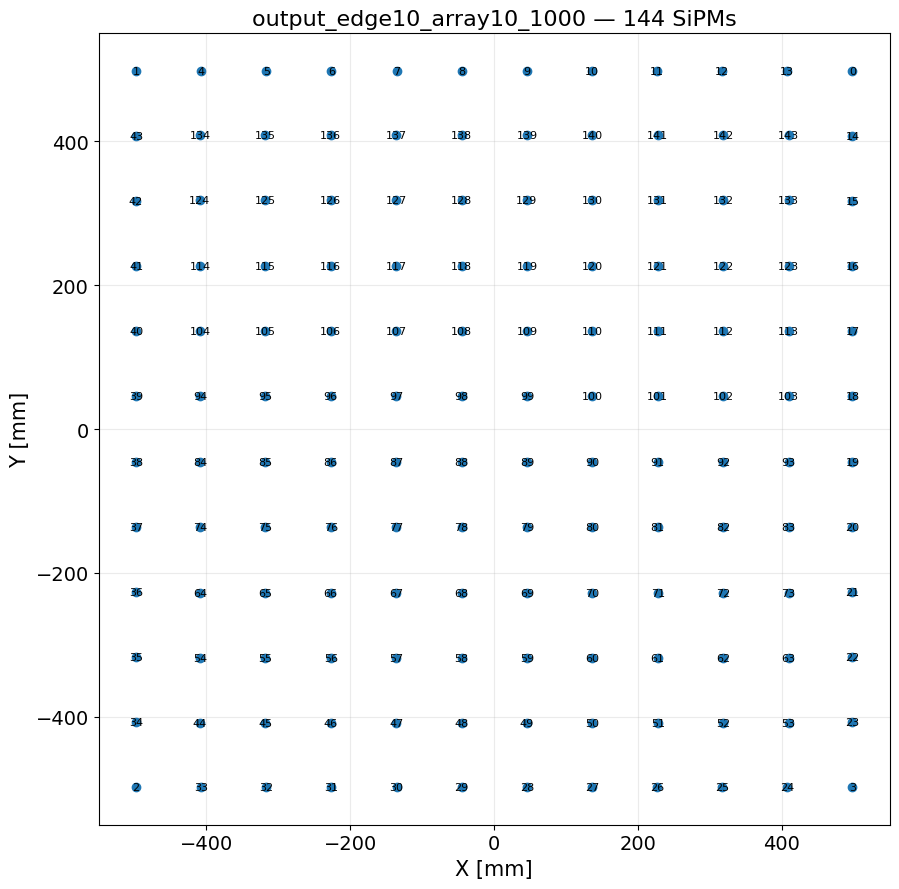

  0 sipm_edge10_array10_1000_0.root            events= 10000
  1 sipm_edge10_array10_1000_1.root            events= 10000
  2 sipm_edge10_array10_1000_10.root           events= 10000
  3 sipm_edge10_array10_1000_11.root           events= 10000
  4 sipm_edge10_array10_1000_12.root           events= 10000
  5 sipm_edge10_array10_1000_13.root           events= 10000
  6 sipm_edge10_array10_1000_14.root           events= 10000
  7 sipm_edge10_array10_1000_15.root           events= 10000
  8 sipm_edge10_array10_1000_16.root           events= 10000
  9 sipm_edge10_array10_1000_17.root           events= 10000
 10 sipm_edge10_array10_1000_18.root           events= 10000
 11 sipm_edge10_array10_1000_19.root           events= 10000
 12 sipm_edge10_array10_1000_2.root            events= 10000
 13 sipm_edge10_array10_1000_3.root            events= 10000
 14 sipm_edge10_array10_1000_4.root            events= 10000
 15 sipm_edge10_array10_1000_5.root            events= 10000
 16 sipm_edge10_array10_

,case,edge,array,length_mm,n_sipm,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,output_edge10_array10_1000,10,10,1000,144,A + t1+t2+t3 ExtraTrees,60000,1.0,11.94,0.01,-0.08,11.98,11.90,11.94,16.19,25.50
1,output_edge10_array10_1000,10,10,1000,144,Amplitude Poisson template,60000,1.0,12.17,-0.01,0.01,12.15,12.19,12.17,16.17,26.05
2,output_edge10_array10_1000,10,10,1000,144,Full ST Poisson (100 ps),60000,1.0,21.14,-0.13,-0.12,21.18,21.09,21.14,28.31,45.03
3,output_edge10_array10_1000,10,10,1000,144,A + t1+t2+t3 HGB,60000,1.0,23.40,0.17,-0.10,23.49,23.30,23.40,34.37,50.05
4,output_edge10_array10_1000,10,10,1000,144,A + t1 HGB,60000,1.0,23.75,0.16,-0.18,23.93,23.57,23.75,34.51,50.91
5,output_edge10_array10_1000,10,10,1000,144,A HGB,60000,1.0,26.35,-0.03,-0.04,26.23,26.48,26.35,37.52,55.97
6,output_edge10_array10_1000,10,10,1000,144,A + dN/dt (100 ps) HGB,60000,1.0,26.45,0.04,-0.07,26.33,26.56,26.45,37.74,56.24
7,output_edge10_array10_1000,10,10,1000,144,COG all SiPMs,60000,1.0,158.68,0.49,-0.20,158.71,158.64,158.68,253.41,319.87
8,output_edge10_array10_1000,10,10,1000,144,COG corners only,60000,1.0,161.79,0.22,-1.47,162.32,161.25,161.79,248.83,334.57


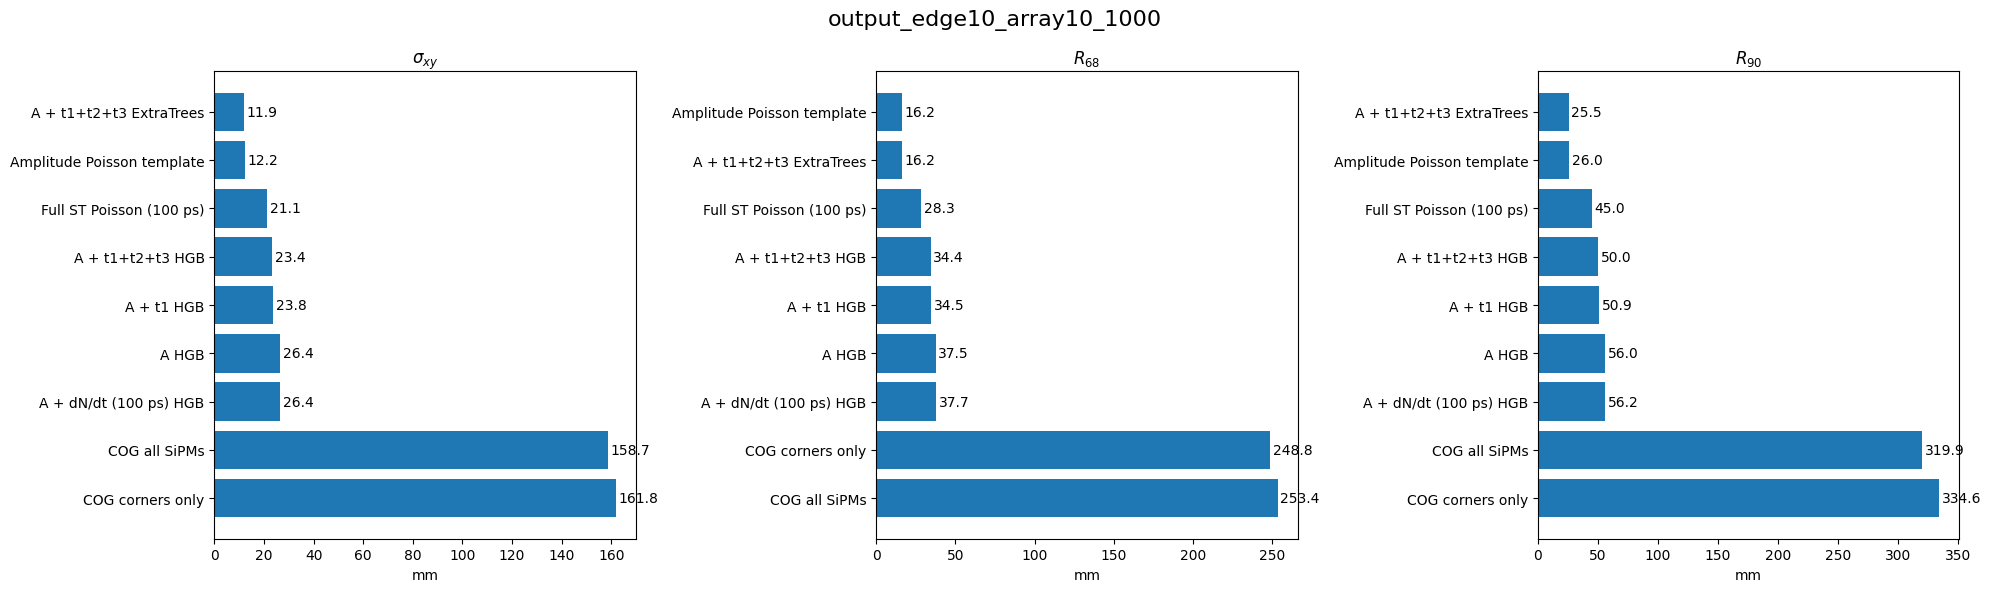

Best by R68: A + t1+t2+t3 ExtraTrees


/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_6486/4167966975.py:305: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  ax[1,0].hist(
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_6486/4167966975.py:309: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  ax[1,0].hist(


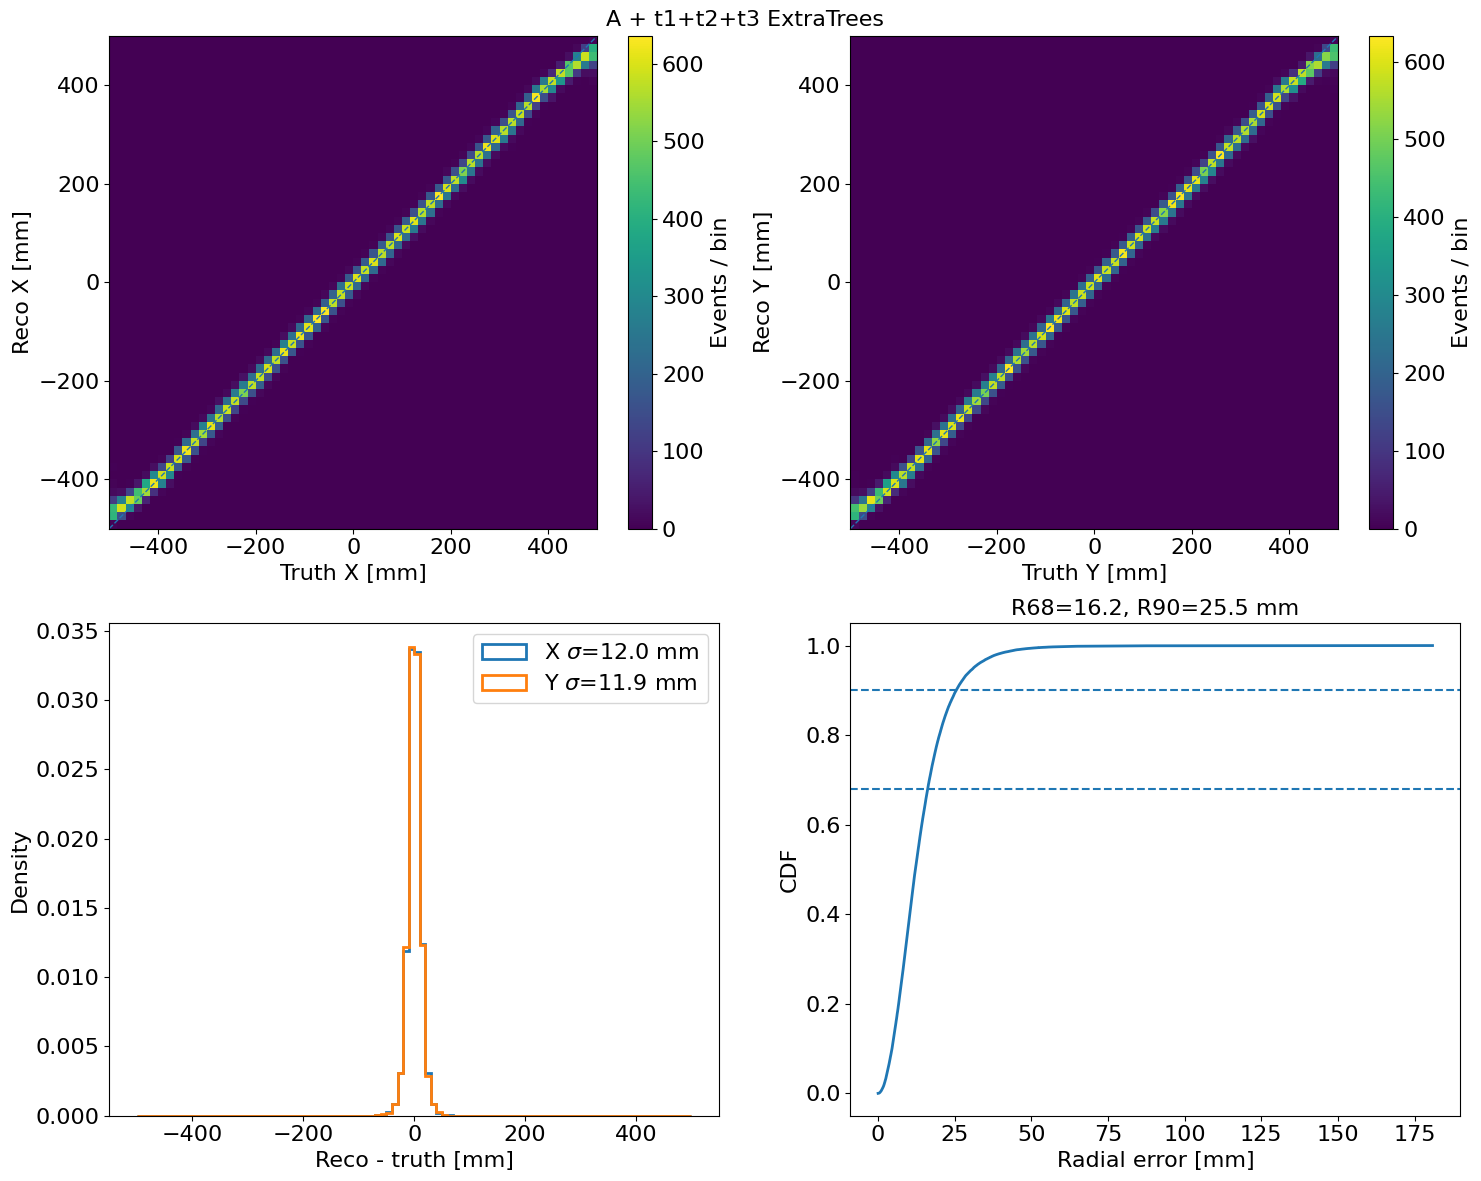

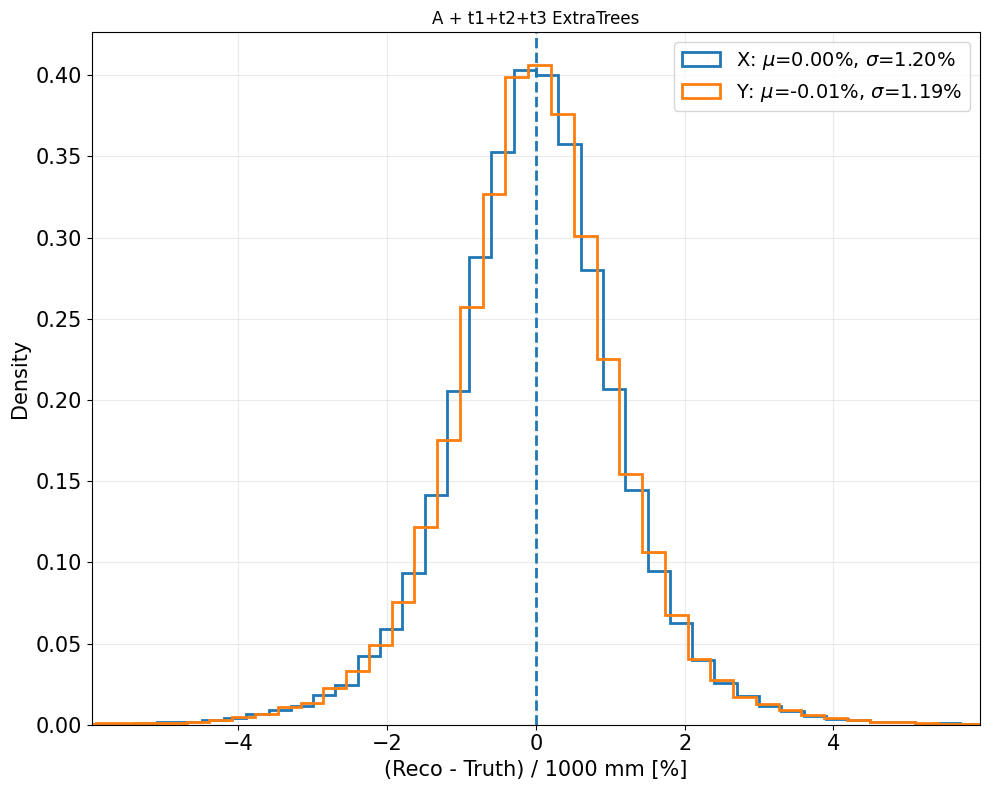

Amplitude-only median CRLB sigma_xy: 5.49 mm
Full ST median CRLB sigma_xy: 0.15 mm


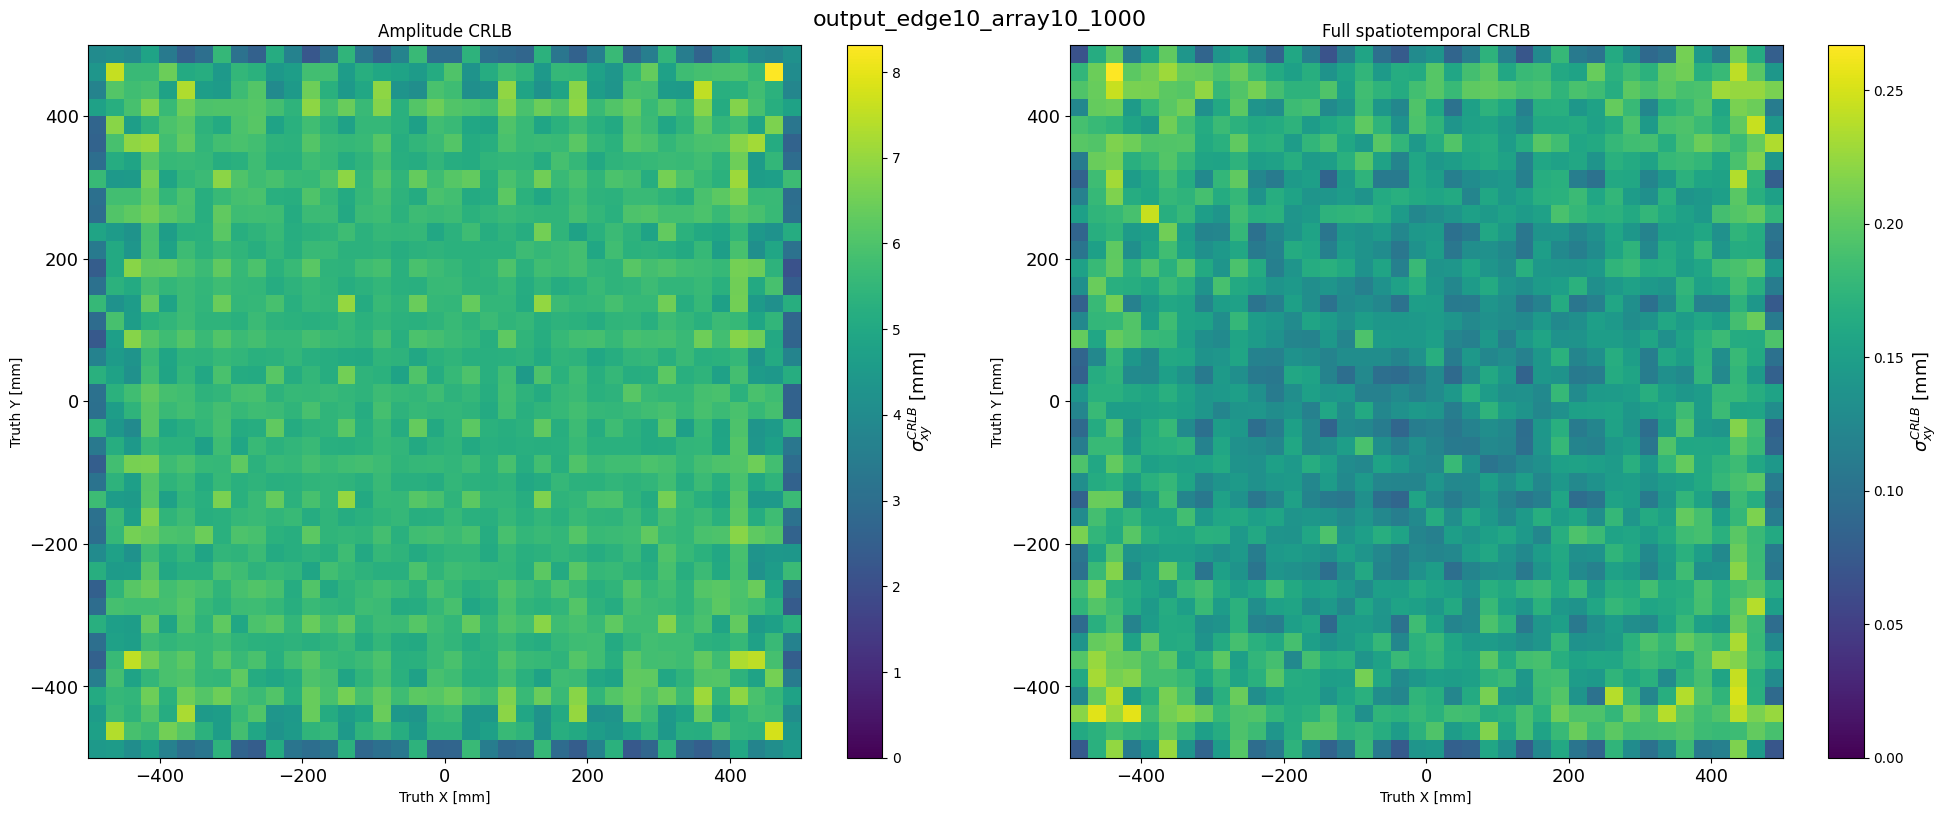

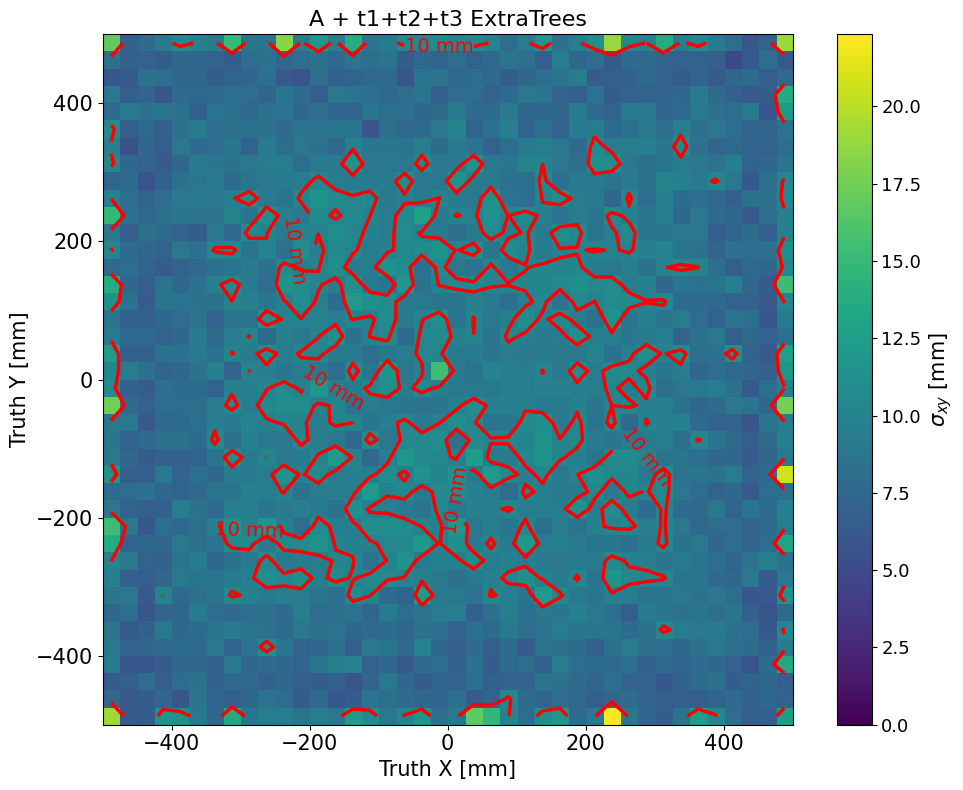

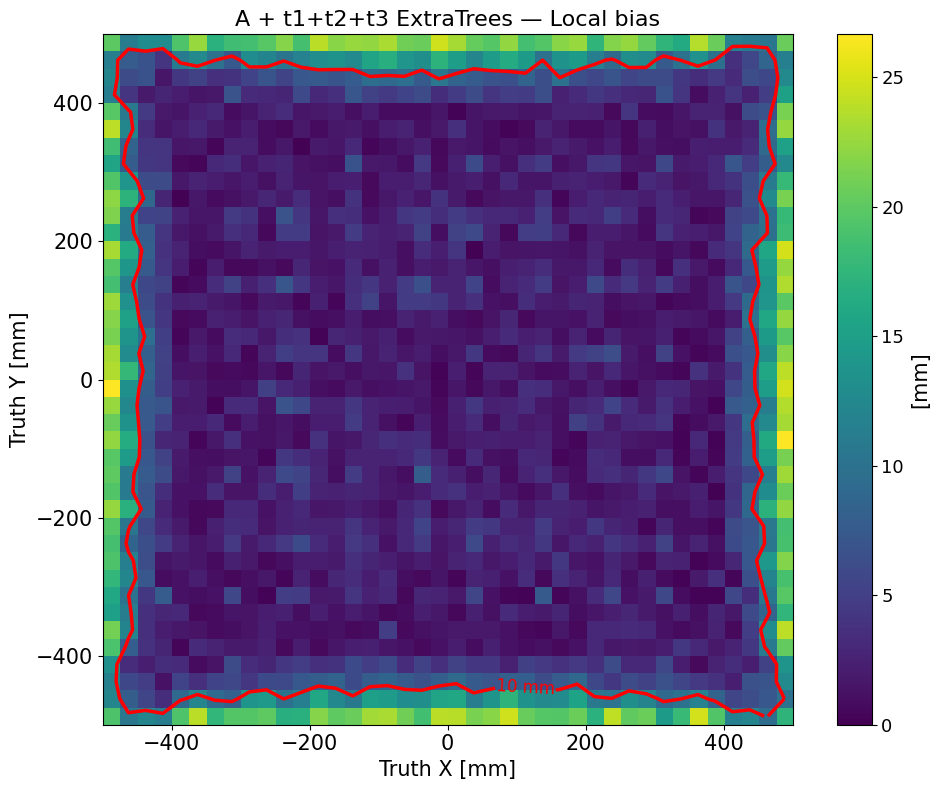

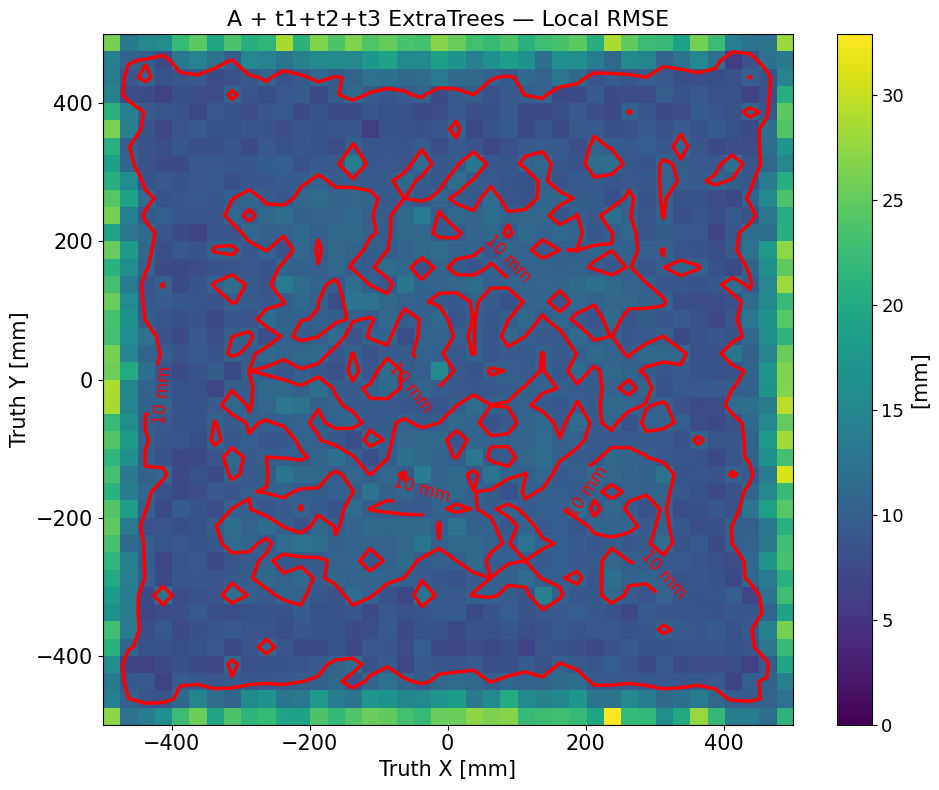


Saved core outputs (same analysis structure as the reference notebook):
   /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/output_edge10_array10_1000_spatiotemporal/spatiotemporal_reconstruction_summary.csv
   /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/output_edge10_array10_1000_spatiotemporal/reconstruction_comparison.png
   /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/output_edge10_array10_1000_spatiotemporal/best_model_performance.png
   /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/output_edge10_array10_1000_spatiotemporal/resolution_sigmaXY.png
   /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/output_edge10_array10_1000_spatiotemporal/approximate_CRLB_maps.png
   /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/output_edge10_array10_1000_spatiotemporal/spatial_resolution_map_best.png
   /Volumes/ExtremeSSD/Soft

,case,edge,array,length_mm,n_sipm,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm,best_method,mean_detected_photons,output_dir
0,output_edge10_array10_1000,10,10,1000,144,A + t1+t2+t3 ExtraTrees,60000,1.0,11.94,0.01,-0.08,11.98,11.9,11.94,16.19,25.5,A + t1+t2+t3 ExtraTrees,983.4,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...


In [140]:

# 4. Batch execution
all_method_summaries = []
best_rows = []
failures = []

for i, case_dir in enumerate(CASE_DIRS, start=1):
    print(f"\n[{i}/{len(CASE_DIRS)}] {case_dir.name}")
    try:
        summary, best = analyze_case(case_dir)
        all_method_summaries.append(summary)
        best_rows.append(best)
    except Exception as exc:
        failures.append({
            "case": case_dir.name,
            "error_type": type(exc).__name__,
            "error": str(exc),
        })
        print(f"FAILED: {type(exc).__name__}: {exc}")
        gc.collect()

BATCH_OUT = BASE / "position_reco_batch_summary"
BATCH_OUT.mkdir(parents=True, exist_ok=True)

if all_method_summaries:
    all_methods = pd.concat(all_method_summaries, ignore_index=True)
    all_methods.to_csv(BATCH_OUT/"all_cases_method_summary.csv", index=False)
else:
    all_methods = pd.DataFrame()

best_summary = pd.DataFrame(best_rows)
if not best_summary.empty:
    best_summary = best_summary.sort_values(
        ["n_sipm", "edge", "array"]
    ).reset_index(drop=True)
    best_summary.to_csv(BATCH_OUT/"all_cases_best_summary.csv", index=False)

failed = pd.DataFrame(failures)
if not failed.empty:
    failed.to_csv(BATCH_OUT/"failed_cases.csv", index=False)

print("\nBatch output:", BATCH_OUT)
display(best_summary.round(2) if not best_summary.empty else best_summary)
if not failed.empty:
    print("\nFailed cases:")
    display(failed)


## Supplemental cross-case comparison

This section is additional to the original single-case notebook. It compares the per-case best reconstruction after all individual analyses have completed.


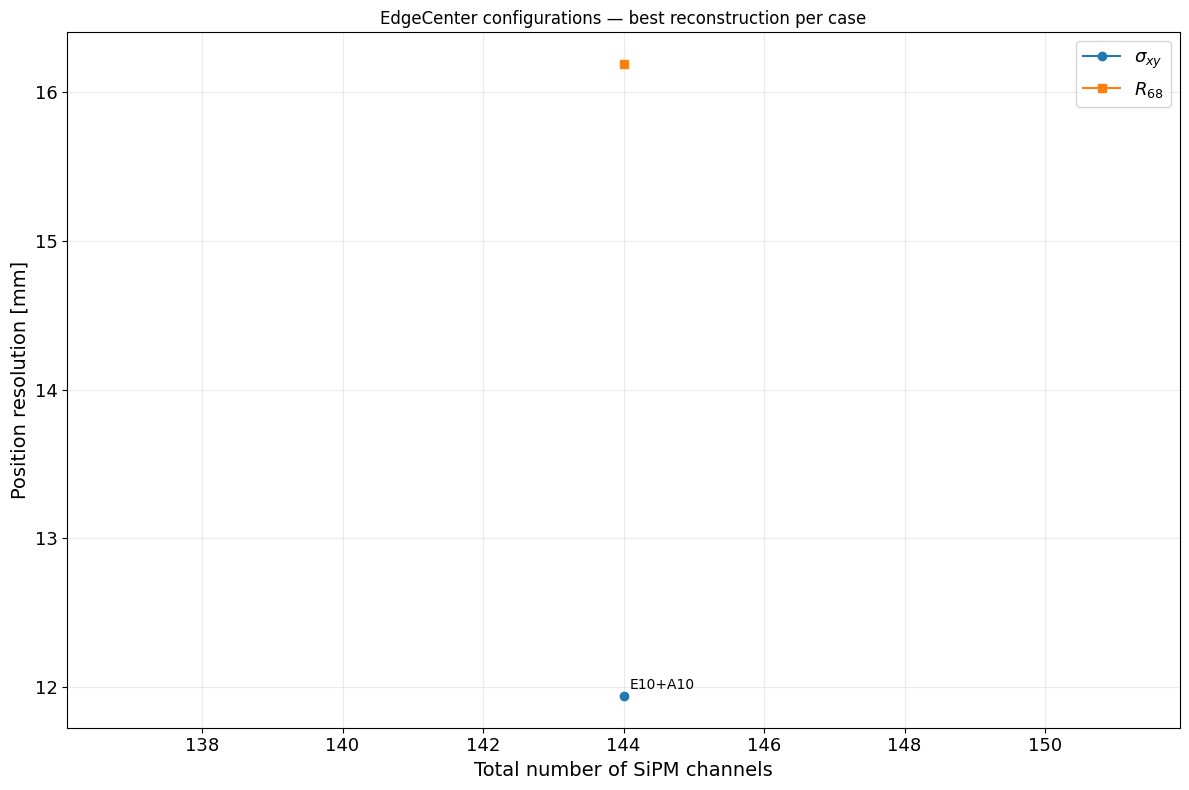

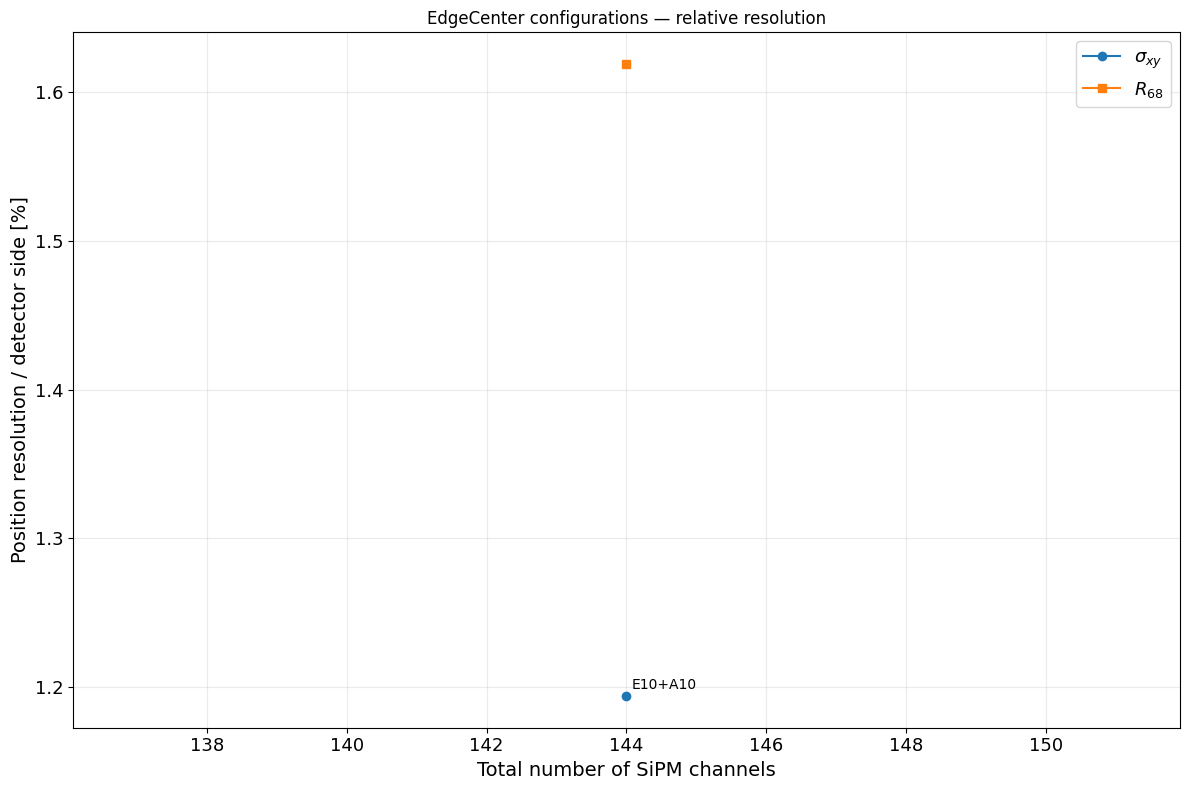

,case,edge,array,n_sipm,best_method,sigma_xy_mm,R68_mm,R90_mm,sigma_xy_pct,R68_pct,mean_detected_photons
0,output_edge10_array10_1000,10,10,144,A + t1+t2+t3 ExtraTrees,11.937,16.19,25.498,1.194,1.619,983.396


In [141]:

# 5. Cross-case summary plots
if best_summary.empty:
    print("No successful cases to summarize.")
else:
    plot_df = best_summary.copy()
    plot_df["setup"] = plot_df.apply(
        lambda r: f"E{int(r.edge)}+A{int(r['array'])}", axis=1
    )

    # Resolution versus channel count
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.plot(
        plot_df["n_sipm"], plot_df["sigma_xy_mm"],
        "o-", label=r"$\sigma_{xy}$"
    )
    ax.plot(
        plot_df["n_sipm"], plot_df["R68_mm"],
        "s-", label=r"$R_{68}$"
    )
    for _, r in plot_df.iterrows():
        ax.annotate(
            r["setup"],
            (r["n_sipm"], r["sigma_xy_mm"]),
            xytext=(4, 5),
            textcoords="offset points",
            fontsize=10
        )
    ax.set(
        xlabel="Total number of SiPM channels",
        ylabel="Position resolution [mm]",
        title="EdgeCenter configurations — best reconstruction per case"
    )
    ax.tick_params(labelsize=13)
    ax.xaxis.label.set_size(14); ax.yaxis.label.set_size(14)
    ax.grid(alpha=.25)
    ax.legend(fontsize=13)
    savefig(fig, BATCH_OUT/"best_resolution_vs_channels.png")

    # Same quantity as percentage of detector side length
    plot_df["sigma_xy_pct"] = 100*plot_df["sigma_xy_mm"]/plot_df["length_mm"]
    plot_df["R68_pct"] = 100*plot_df["R68_mm"]/plot_df["length_mm"]

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.plot(
        plot_df["n_sipm"], plot_df["sigma_xy_pct"],
        "o-", label=r"$\sigma_{xy}$"
    )
    ax.plot(
        plot_df["n_sipm"], plot_df["R68_pct"],
        "s-", label=r"$R_{68}$"
    )
    for _, r in plot_df.iterrows():
        ax.annotate(
            r["setup"],
            (r["n_sipm"], r["sigma_xy_pct"]),
            xytext=(4, 5),
            textcoords="offset points",
            fontsize=10
        )
    ax.set(
        xlabel="Total number of SiPM channels",
        ylabel="Position resolution / detector side [%]",
        title="EdgeCenter configurations — relative resolution"
    )
    ax.tick_params(labelsize=13)
    ax.xaxis.label.set_size(14); ax.yaxis.label.set_size(14)
    ax.grid(alpha=.25)
    ax.legend(fontsize=13)
    savefig(fig, BATCH_OUT/"best_relative_resolution_vs_channels.png")

    display(
        plot_df[
            [
                "case", "edge", "array", "n_sipm", "best_method",
                "sigma_xy_mm", "R68_mm", "R90_mm",
                "sigma_xy_pct", "R68_pct", "mean_detected_photons"
            ]
        ].round(3)
    )



### Recommended usage

For a first check, set:

```python
RUN_ALL_CASES = False
CASE_NAMES = ["output_edge8_array8_1000"]
MAX_ROOT_FILES = 2
RUN_EXTRA_TREES = False
```

Once the ROOT branches and channel count look correct, restore `MAX_ROOT_FILES = None`, enable the desired algorithms, and then set `RUN_ALL_CASES = True`.

The expensive detector-timing scan is intentionally off by default in batch mode because it rereads every ROOT file for every \(\sigma_t\) value.
